---

# **CUSTOMER REVIEW SENTIMENT ANALYSIS**
### Voice-of-Customer Intelligence for a Consumer Electronics Brand

**Prepared by :** Yunido Baheramsyah - Freelance Data Scientist

**Project type :** End-to-end data science case study, written as a freelance client engagement

**Business context :** a U.S.-based direct-to-consumer **consumer electronics** company (audio devices, wearables, smart-home devices and charging accessories) selling through its official webstore and third-party marketplaces in the U.S., Canada and the U.K.

This notebook builds a machine learning model that automatically classifies customer reviews into **positive**, **neutral** or **negative** sentiment, and turns thousands of unstructured reviews into actionable insights for the Product and Customer Experience (CX) teams.

> **About the data:** The dataset was purpose-built for this case study. It replicates the structure, volume, noise (typos, slang, emojis, HTML, duplicates) and business patterns of a real e-commerce review export. See `generate_dummy_data.py` for how the data was created.

---

# **I. INTRODUCTION**

**Background**

The client sells nine flagship products across four categories and receives several hundred customer reviews every month from its own webstore, Amazon, Walmart Marketplace and Best Buy Marketplace. Today, a two-person CX team reads reviews manually and tags them in a spreadsheet. As volume has grown, the team can only review a small sample each week. As a result, product defects and service issues are discovered late, often only after the star rating on the marketplace has already dropped.

The client also wants to analyse **text that has no star rating at all** (support tickets, chat transcripts, social-media mentions and survey comments). A model that reads the *text* and predicts sentiment can be applied to all of these channels, whereas the star rating only exists on review platforms.

**Project Scope**

1. Clean and explore ~6,000 historical reviews (Jan 2024 - Dec 2025) labelled by the CX team.
2. Identify the main drivers of negative sentiment by product, channel and time.
3. Build, compare and tune classification models that predict sentiment from review text and review metadata.
4. Deliver a ready-to-use pipeline (`.pkl`) and a separate inference notebook the client's team can run on new data.

**Problem Statement**

The client needs an accurate and measurable text classification model that predicts the sentiment of a customer review (positive / neutral / negative) from the review text and basic metadata, **without relying on the star rating**. The model must reach a **macro-averaged F1-score of at least 0.80** on unseen data so that it is reliable for the minority classes (neutral and negative), and it must be delivered within **four weeks** as a reusable pipeline that the CX team can run on new reviews.

**Dataset Overview**

| Column | Description |
|---|---|
| `review_id` | Unique review identifier |
| `customer_id` | Anonymised customer identifier |
| `review_date` | Date the review was posted |
| `product_name` | Product reviewed (fictional names) |
| `product_category` | Audio, Wearables, Smart Home, Accessories |
| `sales_channel` | Where the product was purchased / reviewed |
| `customer_region` | Customer region (U.S. regions, Canada, U.K.) |
| `verified_purchase` | Whether the reviewer is a verified buyer |
| `rating` | Star rating (1–5) |
| `helpful_votes` | Number of "helpful" votes the review received |
| `review_title` | Short headline written by the customer |
| `review_text` | Full review text (raw, unprocessed) |
| `sentiment` | **Target** - label assigned by the CX team: positive / neutral / negative |

---

# **II. BUSINESS OBJECTIVES**

1. **Reduce manual workload** — automatically tag 100% of incoming reviews instead of a weekly sample, freeing the CX team to focus on *responding* rather than *reading*.
2. **Detect problems earlier** — surface spikes in negative sentiment by product and channel so that defects (e.g., firmware or app issues) are escalated within days, not months.
3. **Understand what drives dissatisfaction** — quantify which product aspects (connectivity, battery, app, shipping, support, etc.) appear most often in negative reviews to guide the product roadmap and logistics partners.
4. **Extend sentiment monitoring beyond star ratings** — provide a text-only model that can later be applied to support tickets, chat logs and social-media mentions.

---

# **III. SMART METHOD**

| SMART | Definition for this project |
|---|---|
| **Specific** | Build a multi-class classification model that predicts review sentiment (positive / neutral / negative) from review text and metadata, and identify the top drivers of negative sentiment. |
| **Measurable** | Achieve a **macro F1-score ≥ 0.80** on the hold-out test set, with recall on the *negative* class ≥ 0.85 so that unhappy customers are rarely missed. |
| **Achievable** | ~6,000 labelled reviews are available; proven NLP techniques (TF-IDF + linear models) are fast, interpretable and suitable for this data size. |
| **Relevant** | Directly supports the client's goals of reducing manual tagging effort, detecting product issues earlier and protecting marketplace ratings. |
| **Time-bound** | Deliver the cleaned dataset, analysis, trained pipeline and inference notebook within **4 weeks** of project kick-off. |

---

# **IV. IMPORT LIBRARIES**

In [87]:
# Data manipulation
import pandas as pd
import numpy as np
import re
from collections import Counter

# Data visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Statistics
from scipy import stats
from scipy.stats import chi2_contingency, kruskal

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Custom preprocessing module (shared with the inference notebook)
from text_utils import (ReviewPreprocessor, IQRCapper, clean_text,
                        standardize_channel, standardize_verified)

# Model saving
import pickle

# Display & chart settings
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', rc={'grid.color': '#e6e5e0', 'axes.edgecolor': '#c3c2b7'})

# Consistent colours: negative = red, neutral = grey, positive = blue
SENTIMENT_ORDER = ['negative', 'neutral', 'positive']
PALETTE = {'negative': '#e34948', 'neutral': '#9a9890', 'positive': '#2a78d6'}
MAIN_COLOR = '#2a78d6'
RANDOM_STATE = 42

---

# **V. LOAD DATASET**

In [88]:
# Load the review export provided by the client
df_raw = pd.read_csv('data/customer_reviews.csv')

# Display the first 5 rows to understand the structure of the data
df_raw.head()

,review_id,customer_id,review_date,product_name,product_category,sales_channel,customer_region,verified_purchase,rating,helpful_votes,review_title,review_text,sentiment
0,RV-005381,C41615,2024-02-13,AirPulse Pro Earbuds,Audio,Official Webstore,US - South,Yes,4,2.0,Avoid,Worth every penny.,positive
1,RV-001783,C84936,2025-05-18,WaveBox Mini Speaker,Audio,Best Buy Marketplace,US - Northeast,Yes,2,3.0,Not as advertised,Very disappointed. Way overpriced for what u get. Only downside: build quality feels premium.,negative
2,RV-005646,C88379,2024-12-21,AirPulse Pro Earbuds,Audio,Official Webstore,US - West,Yes,5,1.0,Not as advertised,Absolutely love it. Super comfortable even after hours. The support team responded w/in an hour. Gonna buy another o...,positive
3,RV-004372,C71303,2024-11-16,FitTrack S2 Smartwatch,Wearables,Official Webstore,Canada,Yes,4,1.0,Amazing quality,Highly recmomend this watch. Worth every penny. Would buy again.,positive
4,RV-004731,C37696,2025-08-24,HomeLink Smart Plug (2-pack),Smart Home,Amazon,US - Midwest,Yes,5,140.0,Great product,Love these plugs! Customer support was super helpful. Only downside: the box was crushed. Recommend to everyyyone.,positive


In [89]:
# Check the size of the dataset (rows, columns)
df_raw.shape

(6130, 13)

In [90]:
# Data types and non-null counts
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6130 entries, 0 to 6129
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          6130 non-null   str    
 1   customer_id        6130 non-null   str    
 2   review_date        6130 non-null   str    
 3   product_name       6130 non-null   str    
 4   product_category   6130 non-null   str    
 5   sales_channel      6130 non-null   str    
 6   customer_region    5945 non-null   str    
 7   verified_purchase  6069 non-null   str    
 8   rating             6130 non-null   int64  
 9   helpful_votes      6069 non-null   float64
 10  review_title       5822 non-null   str    
 11  review_text        6039 non-null   str    
 12  sentiment          6130 non-null   str    
dtypes: float64(1), int64(1), str(11)
memory usage: 622.7 KB


In [91]:
# Summary statistics for the numerical columns
df_raw.describe()

,rating,helpful_votes
count,6130.000000,6069.000000
mean,3.543230,4.565991
std,1.496886,28.067823
min,1.000000,0.000000
25%,2.000000,0.000000
50%,4.000000,1.000000
75%,5.000000,2.000000
max,5.000000,396.000000


> **Insight:**
- The raw export contains **6,130 rows and 13 columns**: 11 text columns, `rating` (int) and `helpful_votes` (float).
- Several columns have missing values (`review_title`, `customer_region`, `review_text`, `verified_purchase`, `helpful_votes`), so the data needs cleaning before modelling.
- `helpful_votes` is extremely right-skewed: the median is 1 vote, while the maximum is 396 (a few "viral" reviews). This will need outlier handling.
- `rating` is on a 1–5 scale. It is closely tied to the target and will be checked for **data leakage** later.

---

# **VI. DATA CLEANING**

## **1. Duplicate Reviews**

In [92]:
# Count exact duplicate rows (e.g., double-submitted reviews)
print('Duplicate rows       :', df_raw.duplicated().sum())
print('Duplicate review_id  :', df_raw['review_id'].duplicated().sum())

Duplicate rows       : 130
Duplicate review_id  : 130


In [93]:
# Work on a copy so the raw data stays untouched
df = df_raw.copy()

# Drop exact duplicates and keep the first occurrence
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Shape after removing duplicates: (6000, 13)


> **Insight:** 130 exact duplicate rows (≈2.1%) were found. These are reviews submitted twice and would give extra weight to some opinions and leak identical rows into both the train and test sets. After removing them, **6,000 unique reviews** remain.

## **2. Missing Values**

In [94]:
# Number and percentage of missing values per column
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
})
missing[missing['missing_count'] > 0].sort_values('missing_count', ascending=False)

,missing_count,missing_pct
review_title,300,5.0
customer_region,180,3.0
review_text,90,1.5
helpful_votes,60,1.0
verified_purchase,60,1.0


In [95]:
# Reviews with blank text (only spaces) are also effectively missing
blank_text = df['review_text'].fillna('').str.strip().eq('')
print('Reviews with missing or blank text:', blank_text.sum())

Reviews with missing or blank text: 115


In [96]:
# 1) review_text is the main input of the model -> rows without text cannot be used
df = df[~blank_text].copy()

# 2) review_title is optional -> replace missing titles with an empty string
df['review_title'] = df['review_title'].fillna('')

# 3) customer_region -> keep the rows, label as 'Unknown'
df['customer_region'] = df['customer_region'].fillna('Unknown')

# 4) helpful_votes and verified_purchase are left as-is here:
#    they will be imputed INSIDE the model pipeline (fitted on training data only)
#    so that the same logic is applied automatically to new data at inference time.

df.isna().sum()[df.isna().sum() > 0]

verified_purchase    60
helpful_votes        60
dtype: int64

> **Insight:**
- **115 reviews** have no usable text (missing or only spaces). Text is the core input of a sentiment model, so these rows were removed (≈1.9% of the data).
- Missing `review_title` values (5%) were replaced with an empty string, because a title is optional for customers.
- Missing `customer_region` values (3%) were labelled `Unknown` to keep the rows.
- `helpful_votes` and `verified_purchase` (1% each) will be imputed **inside the pipeline**, so the same rule is applied automatically to future data.

## **3. Inconsistent Category Labels**

In [97]:
# Inspect raw spellings of the sales channel and verified-purchase flag
print(df['sales_channel'].value_counts(), '\n')
print(df['verified_purchase'].value_counts(dropna=False))

sales_channel
Amazon                  1994
Official Webstore       1513
Walmart Marketplace      932
Best Buy Marketplace     596
amazon                    93
AMAZON                    88
Amazon.com                81
official webstore         73
 Amazon                   73
Webstore                  69
walmart                   65
Official Webstore         59
Walmart                   51
WEBSTORE                  51
WALMART MARKETPLACE       49
Best Buy                  34
bestbuy                   33
best buy marketplace      31
Name: count, dtype: int64 

verified_purchase
Yes      4311
No        926
no        113
TRUE      105
yes       102
FALSE      99
Y          88
N          81
NaN        60
Name: count, dtype: int64


In [98]:
# Standardize using the helper functions from text_utils.py
df['sales_channel'] = df['sales_channel'].apply(standardize_channel)
df['verified_purchase'] = df['verified_purchase'].apply(standardize_verified)

print(df['sales_channel'].value_counts(), '\n')
print(df['verified_purchase'].value_counts())

sales_channel
Amazon                  2329
Official Webstore       1765
Walmart Marketplace     1097
Best Buy Marketplace     694
Name: count, dtype: int64 

verified_purchase
Yes        4606
No         1219
Unknown      60
Name: count, dtype: int64


> **Insight:** The same channel appeared under up to six different spellings (e.g., `Amazon`, `AMAZON`, ` Amazon`, `Amazon.com`), and the verified flag mixed `Yes/Y/TRUE/yes`. Without standardisation, one channel would be split into several categories and the analysis by channel would be wrong. After cleaning there are **4 sales channels** and **3 verified-purchase values** (`Yes`, `No`, `Unknown`).

## **4. Data Types**

In [99]:
# Convert review_date to datetime and create a year-month column for trend analysis
df['review_date'] = pd.to_datetime(df['review_date'])
df['year_month'] = df['review_date'].dt.to_period('M')

# Reset index and check the final structure
df = df.reset_index(drop=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5885 entries, 0 to 5884
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   review_id          5885 non-null   str           
 1   customer_id        5885 non-null   str           
 2   review_date        5885 non-null   datetime64[us]
 3   product_name       5885 non-null   str           
 4   product_category   5885 non-null   str           
 5   sales_channel      5885 non-null   str           
 6   customer_region    5885 non-null   str           
 7   verified_purchase  5885 non-null   str           
 8   rating             5885 non-null   int64         
 9   helpful_votes      5825 non-null   float64       
 10  review_title       5885 non-null   str           
 11  review_text        5885 non-null   str           
 12  sentiment          5885 non-null   str           
 13  year_month         5885 non-null   period[M]     
dtypes: datetime64[us](1

> **Insight:** `review_date` was converted to `datetime` and a `year_month` column was added for trend analysis. The clean dataset now contains **5,885 reviews** with no missing values except `helpful_votes`, which is handled in the pipeline.

---

# **VII. EXPLORATORY DATA ANALYSIS (EDA)**

## **1. Target Distribution: Sentiment**

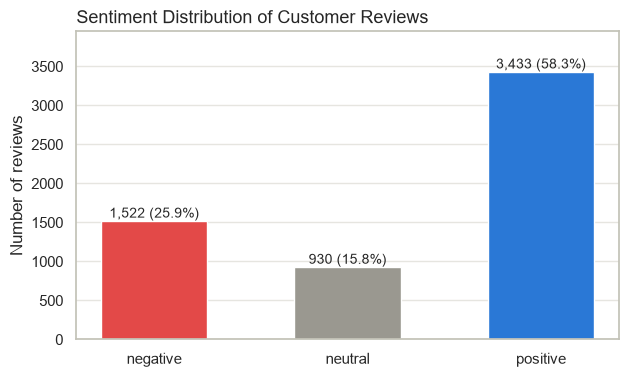

sentiment
negative    25.9
neutral     15.8
positive    58.3
Name: count, dtype: float64

In [100]:
sent_counts = df['sentiment'].value_counts().reindex(SENTIMENT_ORDER)
sent_pct = (sent_counts / sent_counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(sent_counts.index, sent_counts.values,
              color=[PALETTE[s] for s in sent_counts.index], width=0.55)
for b, n, p in zip(bars, sent_counts.values, sent_pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 40, f'{n:,} ({p}%)',
            ha='center', fontsize=10)
ax.set_title('Sentiment Distribution of Customer Reviews', loc='left', fontsize=13)
ax.set_ylabel('Number of reviews')
ax.set_ylim(0, sent_counts.max() * 1.15)
ax.grid(axis='x', visible=False)
plt.show()

sent_pct

> **Insight:** The data is **imbalanced**: 58.3% of reviews are positive, 25.9% negative and only 15.8% neutral. A model could reach ~58% accuracy by always predicting "positive", so **accuracy is not a reliable metric** here. The project uses **macro F1** and balanced class weights instead. Neutral is the smallest and also the most ambiguous class, so it is expected to be the hardest to predict.

## **2. Star Rating vs. Labelled Sentiment**

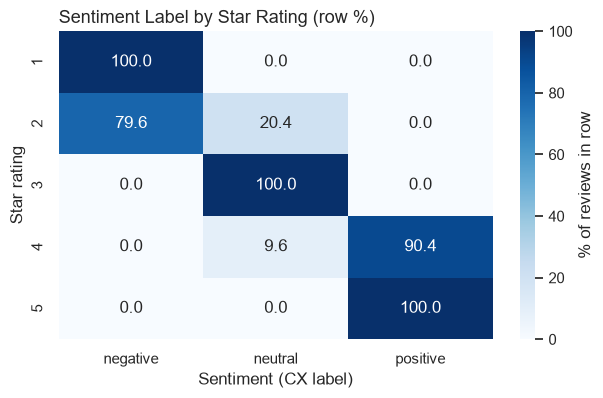

In [101]:
ct = pd.crosstab(df['rating'], df['sentiment'], normalize='index')[SENTIMENT_ORDER] * 100

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of reviews in row'}, ax=ax)
ax.set_title('Sentiment Label by Star Rating (row %)', loc='left', fontsize=13)
ax.set_xlabel('Sentiment (CX label)')
ax.set_ylabel('Star rating')
plt.show()

> **Insight:** The star rating almost fully determines the CX label: 1 and 5 stars map 100% to negative and positive, and 3 stars are always neutral. Ratings of 2 and 4 are the only "mixed" cases. Using `rating` as a feature would give an unrealistically high score (**data leakage**). It would also make the model useless for the client's second goal: scoring support tickets, chats and social posts, **which have no star rating**. `rating` is therefore **excluded** from the model.

## **3. Sentiment by Product**

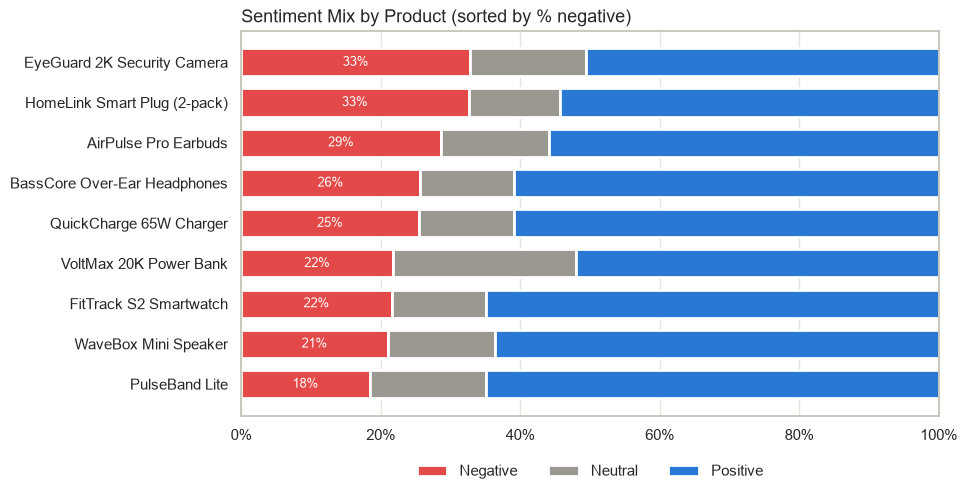

sentiment,negative,neutral,positive
product_name,,,
EyeGuard 2K Security Camera,32.9,16.6,50.5
HomeLink Smart Plug (2-pack),32.6,13.1,54.2
AirPulse Pro Earbuds,28.6,15.5,55.8
BassCore Over-Ear Headphones,25.6,13.5,60.9
QuickCharge 65W Charger,25.5,13.7,60.8
VoltMax 20K Power Bank,21.8,26.2,52.0
FitTrack S2 Smartwatch,21.6,13.5,64.9
WaveBox Mini Speaker,21.0,15.3,63.7
PulseBand Lite,18.5,16.7,64.9


In [102]:
prod = (pd.crosstab(df['product_name'], df['sentiment'], normalize='index')[SENTIMENT_ORDER] * 100)
prod = prod.sort_values('negative')

fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(prod))
for s in SENTIMENT_ORDER:
    ax.barh(prod.index, prod[s], left=left, color=PALETTE[s], label=s.title(),
            edgecolor='white', linewidth=2, height=0.7)
    for y, (l, v) in enumerate(zip(left, prod[s])):
        if s == 'negative' and v > 6:
            ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9)
    left += prod[s].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.set_title('Sentiment Mix by Product (sorted by % negative)', loc='left', fontsize=13)
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.grid(axis='y', visible=False)
plt.show()

prod.round(1).sort_values('negative', ascending=False)

> **Insight:**
- The two **Smart Home** products have the highest share of negative reviews: **EyeGuard 2K Security Camera (32.9%)** and **HomeLink Smart Plug (32.6%)**, about 11–14 points more than the best-rated products.
- **AirPulse Pro Earbuds**, the best-selling product, ranks third (28.6%). The time analysis below shows this comes from a specific period.
- **VoltMax 20K Power Bank** has few negative reviews but the **highest neutral share (26.2%)**. Customers are lukewarm rather than angry, which usually points to a price/value perception issue.
- **PulseBand Lite**, **FitTrack S2** and **WaveBox Mini** have the healthiest sentiment profile.

## **4. Negative Sentiment Over Time**

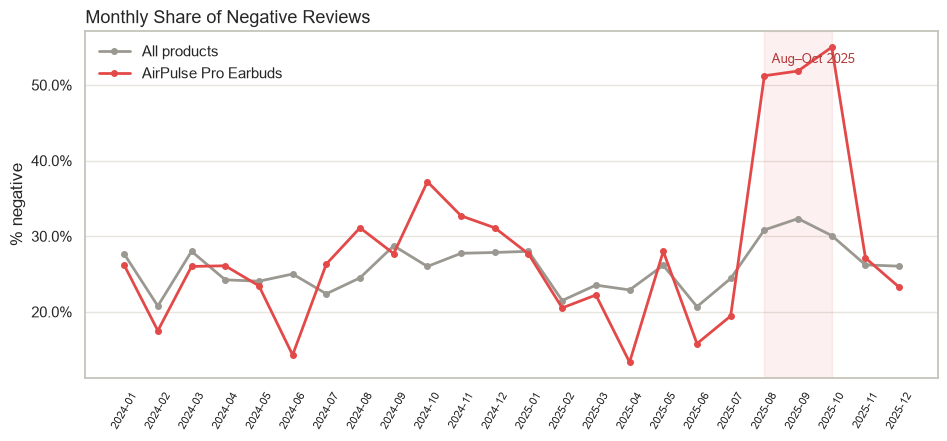

In [103]:
monthly = df.groupby('year_month').agg(
    reviews=('sentiment', 'size'),
    neg_share=('sentiment', lambda s: (s == 'negative').mean() * 100))

earbuds = df[df['product_name'] == 'AirPulse Pro Earbuds'].groupby('year_month').agg(
    neg_share=('sentiment', lambda s: (s == 'negative').mean() * 100))

fig, ax = plt.subplots(figsize=(11, 4.5))
x = monthly.index.astype(str)
ax.plot(x, monthly['neg_share'], color='#9a9890', lw=2, marker='o', ms=4, label='All products')
ax.plot(earbuds.index.astype(str), earbuds['neg_share'], color='#e34948', lw=2, marker='o', ms=4,
        label='AirPulse Pro Earbuds')
ax.axvspan('2025-08', '2025-10', color='#e34948', alpha=0.08)
ax.text('2025-08', ax.get_ylim()[1] * 0.95, '  Aug–Oct 2025', color='#b23a39', fontsize=9, va='top')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Monthly Share of Negative Reviews', loc='left', fontsize=13)
ax.set_ylabel('% negative')
plt.xticks(rotation=60, fontsize=8)
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
plt.show()

In [104]:
# What do customers complain about in the earbuds during the spike vs. the rest of the period?
eb = df[df['product_name'] == 'AirPulse Pro Earbuds'].copy()
eb['period'] = np.where(eb['review_date'].between('2025-08-01', '2025-10-31'), 'Aug-Oct 2025', 'Other months')
eb['mentions_connection'] = eb['review_text'].str.contains(
    r'disconnect|connection|pairing|bluetooth|cuts out|cutting out', case=False, na=False)

eb[eb['sentiment'] == 'negative'].groupby('period')['mentions_connection'].mean().mul(100).round(1).rename(
    '% of negative earbud reviews mentioning connectivity')

period
Aug-Oct 2025    67.1
Other months    21.5
Name: % of negative earbud reviews mentioning connectivity, dtype: float64

> **Insight:** Negative sentiment for all products stays stable at ~21–29% per month. The **AirPulse Pro Earbuds** are the exception: their negative share jumps from ~20% to **51–55% between August and October 2025**, then returns to normal in November. During the spike, **67% of negative earbud reviews mention connectivity** (disconnecting, pairing, Bluetooth), compared with 21% in other months. This points to a specific technical issue (e.g., a firmware update) rather than general dissatisfaction.
>
> **Business value:** With automated sentiment monitoring, an alert on this spike could have been raised in the **first weeks of August** instead of being found through manual sampling months later.

## **5. Sales Channel & Holiday Season**

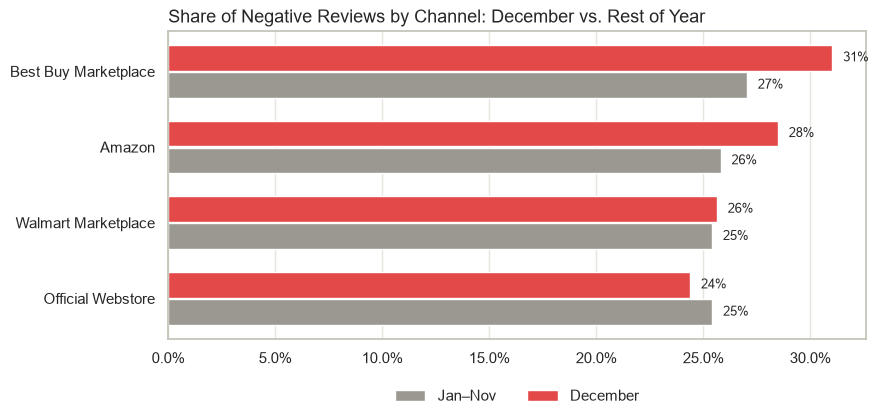

In [105]:
df['season'] = np.where(df['review_date'].dt.month == 12, 'December', 'Jan–Nov')
ch = (df.assign(is_neg=df['sentiment'].eq('negative'))
        .pivot_table(index='sales_channel', columns='season', values='is_neg', aggfunc='mean') * 100)
ch = ch[['Jan–Nov', 'December']].sort_values('December')

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(ch))
ax.barh(y - 0.18, ch['Jan–Nov'], height=0.34, color='#9a9890', label='Jan–Nov')
ax.barh(y + 0.18, ch['December'], height=0.34, color='#e34948', label='December')
for i, (a, b) in enumerate(zip(ch['Jan–Nov'], ch['December'])):
    ax.text(a + 0.5, i - 0.18, f'{a:.0f}%', va='center', fontsize=9)
    ax.text(b + 0.5, i + 0.18, f'{b:.0f}%', va='center', fontsize=9)
ax.set_yticks(y, ch.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Share of Negative Reviews by Channel: December vs. Rest of Year', loc='left', fontsize=13)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='y', visible=False)
plt.show()

> **Insight:** In December, the share of negative reviews rises on **Best Buy Marketplace (+4 pts)** and **Amazon (+2.5 pts)**, while the **Official Webstore stays flat or even improves**. This fits a pattern of holiday shipping delays on third-party fulfilment. The effect is modest, and the Chi-square test below shows that `sales_channel` is **not** a significant predictor of sentiment on its own. It is still useful for operations to review the marketplace logistics SLA before the next holiday season.

## **6. Review Length & Helpful Votes by Sentiment**

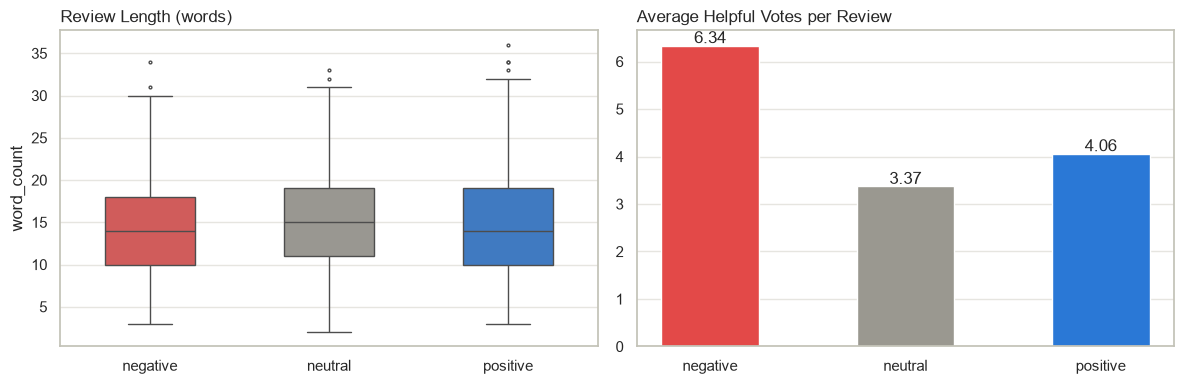

,word_count,helpful_votes
sentiment,,
negative,14.0,2.0
neutral,15.0,1.0
positive,14.0,1.0


In [106]:
df['word_count'] = df['review_text'].apply(lambda t: len(str(t).split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='sentiment', y='word_count', order=SENTIMENT_ORDER, palette=PALETTE,
            width=0.5, fliersize=2, ax=axes[0])
axes[0].set_title('Review Length (words)', loc='left')
axes[0].set_xlabel('')

hv = df.groupby('sentiment')['helpful_votes'].mean().reindex(SENTIMENT_ORDER)
axes[1].bar(hv.index, hv.values, color=[PALETTE[s] for s in hv.index], width=0.5)
for i, v in enumerate(hv.values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center')
axes[1].set_title('Average Helpful Votes per Review', loc='left')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

df.groupby('sentiment')[['word_count', 'helpful_votes']].median()

> **Insight:**
- Review length is similar across the three classes (median 14–15 words), so length alone is a weak signal. Neutral reviews are slightly longer because customers explain both pros and cons.
- Negative reviews receive more **helpful votes** on average (6.3 vs. 3.4–4.1). Other shoppers find complaints more useful, so unaddressed negative reviews have an outsized influence on purchase decisions. Note that the averages are inflated by a few viral reviews (outliers are handled later).

## **7. Most Frequent Words per Sentiment**

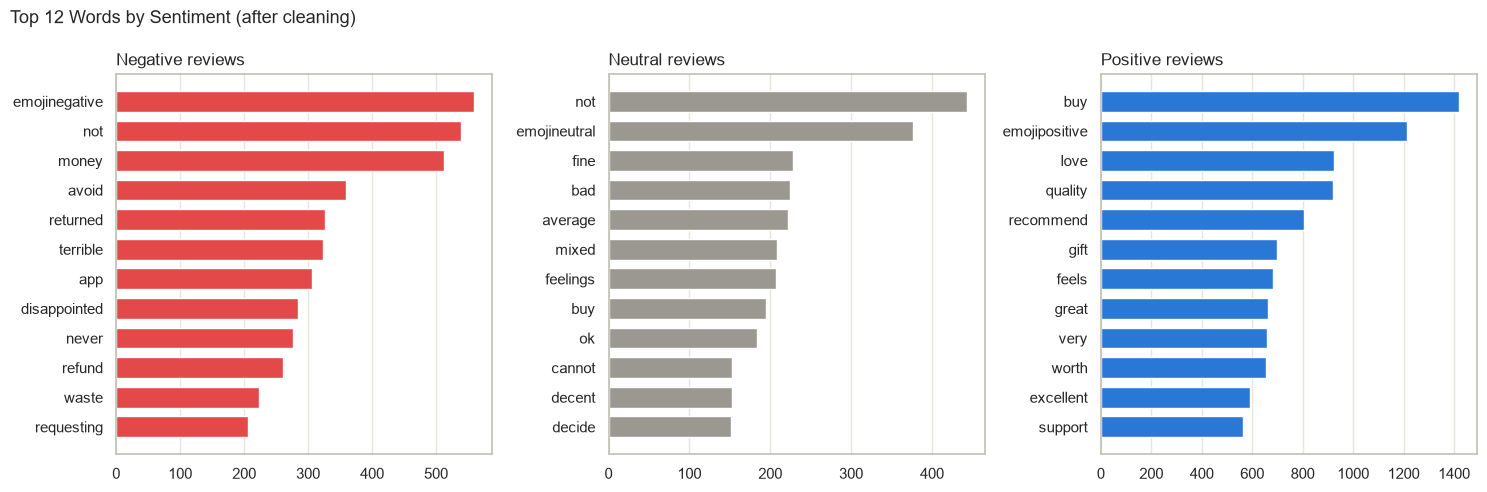

In [107]:
# Clean the text (same function used later in the pipeline) and count words per class
df['clean_text'] = (df['review_title'] + '. ' + df['review_text']).apply(clean_text)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, s in zip(axes, SENTIMENT_ORDER):
    words = Counter(' '.join(df.loc[df['sentiment'] == s, 'clean_text']).split()).most_common(12)
    w, c = zip(*words)
    ax.barh(w[::-1], c[::-1], color=PALETTE[s], height=0.7)
    ax.set_title(f'{s.title()} reviews', loc='left', fontsize=12)
    ax.grid(axis='y', visible=False)
plt.suptitle('Top 12 Words by Sentiment (after cleaning)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

> **Insight:**
- **Negative** reviews are dominated by action and emotion words: *avoid, returned, terrible, disappointed, refund, waste*. *App* also appears in the top words, which confirms the app issues seen for Smart Home devices.
- **Neutral** reviews use hedging words: *fine, average, ok, decent, mixed feelings, cannot decide*.
- **Positive** reviews focus on *love, quality, recommend, gift, worth, excellent*.
- Keeping negation words (*not*, *never*) during cleaning was the right choice. *not* is a top word for both negative and neutral reviews (*not worth*, *not bad*), and bigrams in TF-IDF will capture these patterns.
- Emoji tokens (`emojinegative`, `emojineutral`, `emojipositive`) are among the strongest signals, so converting emojis to tokens instead of deleting them adds value.

## **8. Complaint Drivers: Which Aspects Appear in Negative Reviews?**

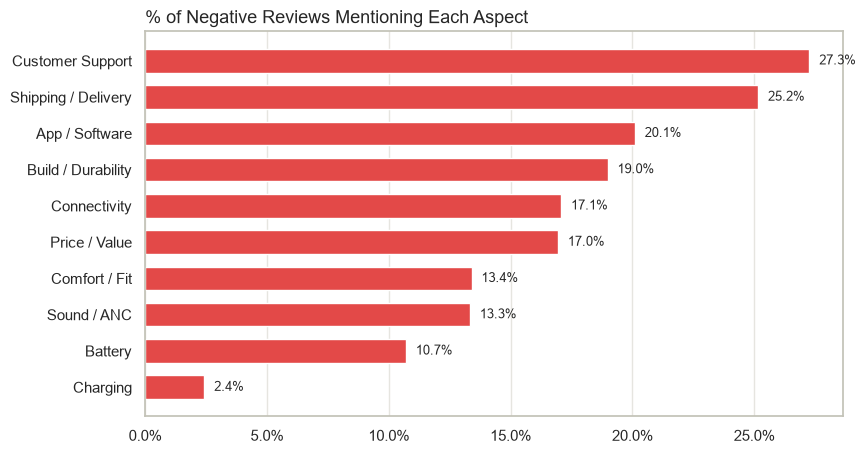

In [108]:
# Simple keyword dictionary to map review text to product/service aspects
ASPECTS = {
    'Connectivity': r'disconnect|connection|pairing|bluetooth|cuts out|cutting out|wifi',
    'App / Software': r'\bapp\b|crash|sync|logs me out',
    'Battery': r'battery|charge\b|drains',
    'Shipping / Delivery': r'shipping|delivery|arrived|package|ship',
    'Customer Support': r'support|customer service|refund',
    'Build / Durability': r'build|cheap|flimsy|broke|cracked|frayed|\bport\b|durable',
    'Price / Value': r'overpriced|not worth|waste of money|price',
    'Sound / ANC': r'sound|audio|bass|noise|anc|hiss',
    'Charging': r'charging|charges|hot',
    'Comfort / Fit': r'comfort|hurts|falling out|rash|fit',
}

neg = df[df['sentiment'] == 'negative']
aspect_share = pd.Series({a: neg['review_text'].str.contains(p, case=False, regex=True).mean() * 100
                          for a, p in ASPECTS.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(aspect_share.index, aspect_share.values, color='#e34948', height=0.65)
for i, v in enumerate(aspect_share.values):
    ax.text(v + 0.4, i, f'{v:.1f}%', va='center', fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('% of Negative Reviews Mentioning Each Aspect', loc='left', fontsize=13)
ax.grid(axis='y', visible=False)
plt.show()

> **Insight:** The most frequent complaint drivers are **Customer Support (27%)** and **Shipping / Delivery (25%)**. These are service issues, not product defects, and can be fixed quickly through support SLAs and logistics partners. Next come **App / Software (20%)**, **Build / Durability (19%)** and **Connectivity (17%)**. For Smart Home products specifically, **62% of negative reviews mention the app**, which makes the companion app the top priority for that product line.

---

# **VIII. FEATURE ENGINEERING**

## **1. Text-Based Feature Creation**

The model will receive **raw** reviews. A custom transformer, `ReviewPreprocessor` (in `text_utils.py`), converts each raw record into model-ready features. Because it is part of the pipeline, the exact same steps run automatically at inference time:

| New feature | How it is built | Why |
|---|---|---|
| `clean_text` | title + text → remove HTML/URLs → emojis to tokens (`emojipositive`, `emojinegative`) → lowercase → normalize slang (`gr8` → great) → shorten elongated words (`sooo` → so) → remove punctuation & stop words **while keeping negations** (`not`, `never`, `but`) | Main input for TF-IDF |
| `word_count` | Number of words in the review | Negative reviews tend to be longer |
| `exclaim_count` | Number of `!` | Emotional intensity |
| `upper_ratio` | Share of upper-case letters | "Shouting" in angry reviews |

In [109]:
# Example: raw text vs. cleaned text
examples = df_raw.loc[df_raw['review_text'].str.contains('<br|http|😡|gr8|sooo', na=False),
                      ['review_title', 'review_text']].head(5)
preview = ReviewPreprocessor().transform(examples)
preview[['review_text', 'clean_text', 'word_count', 'exclaim_count', 'upper_ratio']]

,review_text,clean_text,word_count,exclaim_count,upper_ratio
8,customer support was super helpful.<br><br>but the package arrived late and damaged. packaging was neat and eco-frie...,great product customer support super helpful but package arrived late damaged packaging neat eco friendly gonna buy ...,26,0,0.000000
29,"Mixed feelings about these earbuds.<br/>Battery gets me through the day, barely. Sound quality blew me away. Might k...",decent mixed feelings earbuds battery gets day barely sound quality blew away,19,0,0.041237
32,The app is clean and easy to use.<br/>Support replaced it with no questions asked. Would buy again.,amazing quality app clean easy use support replaced no questions asked buy,17,0,0.038961
42,Mixed feelings about this watch.<br><br>Comfort is ok for short sessions. The battery lasts way longer than my old one.,not bad mixed feelings watch comfort ok short sessions battery lasts way longer old,19,0,0.031915
53,it's ok.<br><br>gets extremely hot while charging. not worth the money.,not bad ok gets extremely hot charging not worth money,10,0,0.000000


## **2. Cardinality Check**

In [110]:
def cardinality_check(data, list_cols):
    '''Return the number of unique values and a sample of unique values per column.'''
    rows = []
    for col in list_cols:
        rows.append([col, data[col].nunique(), data[col].unique()[:6]])
    return pd.DataFrame(rows, columns=['column_name', 'n_unique', 'sample_unique_values'])

cardinality_check(df, ['review_id', 'customer_id', 'review_date', 'product_name', 'product_category',
                       'sales_channel', 'customer_region', 'verified_purchase', 'rating',
                       'helpful_votes', 'review_title', 'review_text', 'sentiment'])

,column_name,n_unique,sample_unique_values
0,review_id,5885,"[RV-005381, RV-001783, RV-005646, RV-004372, RV-004731, RV-001408]"
1,customer_id,5681,"[C41615, C84936, C88379, C71303, C37696, C51195]"
2,review_date,730,"[2024-02-13 00:00:00, 2025-05-18 00:00:00, 2024-12-21 00:00:00, 2024-11-16 00:00:00, 2025-08-24 00:00:00, 2025-08-18..."
3,product_name,9,"[AirPulse Pro Earbuds, WaveBox Mini Speaker, FitTrack S2 Smartwatch, HomeLink Smart Plug (2-pack), VoltMax 20K Power..."
4,product_category,4,"[Audio, Wearables, Smart Home, Accessories]"
5,sales_channel,4,"[Official Webstore, Best Buy Marketplace, Amazon, Walmart Marketplace]"
6,customer_region,7,"[US - South, US - Northeast, US - West, Canada, US - Midwest, UK]"
7,verified_purchase,3,"[Yes, No, Unknown]"
8,rating,5,"[4, 2, 5, 1, 3]"
9,helpful_votes,88,"[2.0, 3.0, 1.0, 140.0, 5.0, 0.0]"


> **Insight:**
- `review_id` (5,885 unique) and `customer_id` (5,681 unique) are identifiers with very high cardinality. They have no predictive meaning and will be dropped.
- `review_text` is almost unique per row (free text). It will be converted to numeric features with **TF-IDF**, not one-hot encoding.
- `product_category` (4), `sales_channel` (4), `customer_region` (7) and `verified_purchase` (3) are low-cardinality nominal features, suitable for **One-Hot Encoding**.
- `review_title` has only 22 unique values (short standard headlines), so it is merged with the review text instead of being treated as a category.
- `product_name` (9) is nested inside `product_category` (4).

## **3. Split the Data**

In [111]:
# Keep only the RAW columns the pipeline needs; feature selection is validated below
candidate_cols = ['review_title', 'review_text', 'helpful_votes', 'verified_purchase',
                  'product_category', 'sales_channel', 'customer_region']

X = df[candidate_cols]
y = df['sentiment']

# 80% train / 20% test, stratified to keep the same class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
pd.DataFrame({'train %': y_train.value_counts(normalize=True).mul(100).round(1),
              'test %': y_test.value_counts(normalize=True).mul(100).round(1)})

X_train: (4708, 7) | X_test: (1177, 7)


,train %,test %
sentiment,,
positive,58.3,58.4
negative,25.9,25.8
neutral,15.8,15.8


> **Insight:** The data was split **80/20 (4,708 train / 1,177 test)** with `stratify=y`, so both sets keep the same class proportions (58% / 26% / 16%). All later steps, including outlier boundaries, imputation values, TF-IDF vocabulary and scaling, are learned on the **training set only** to avoid data leakage.

## **4. Outlier Detection & Handling**

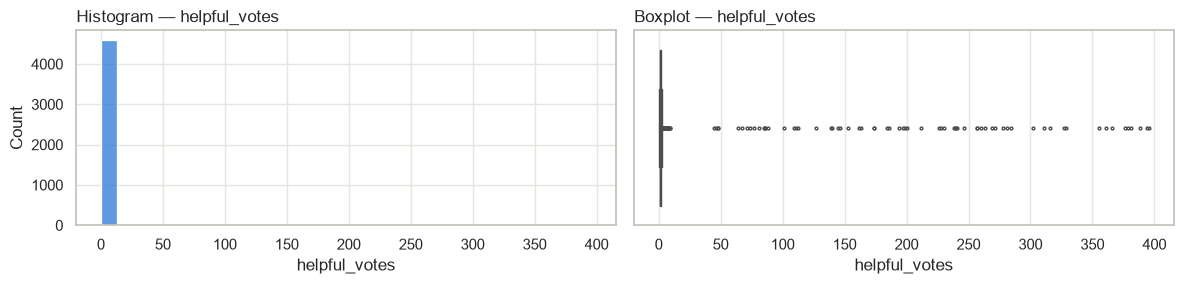

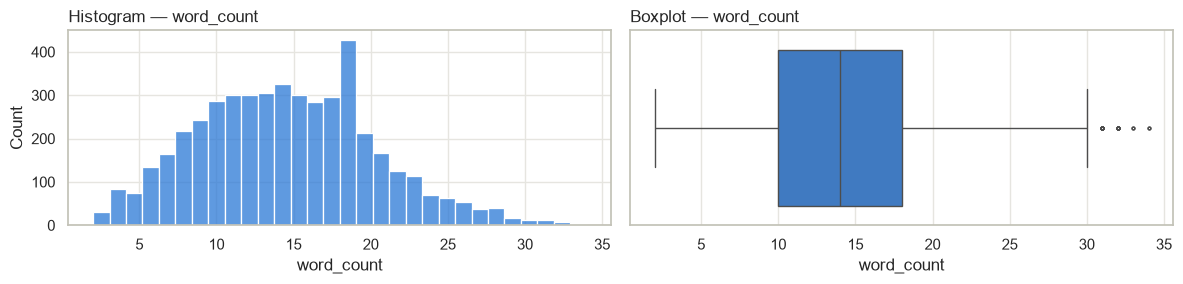

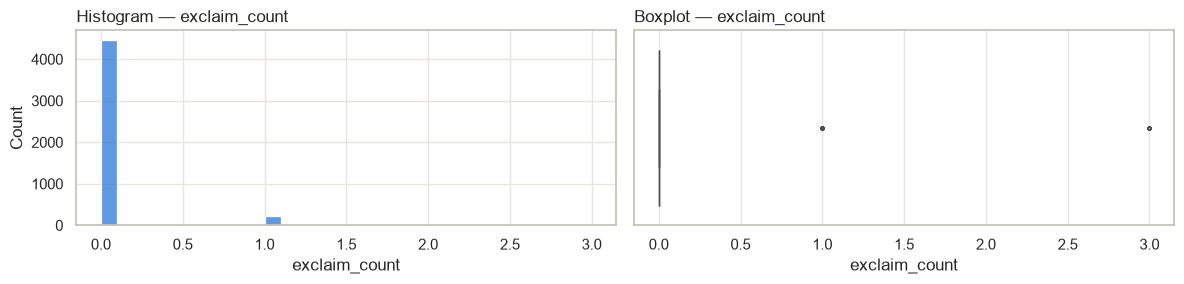

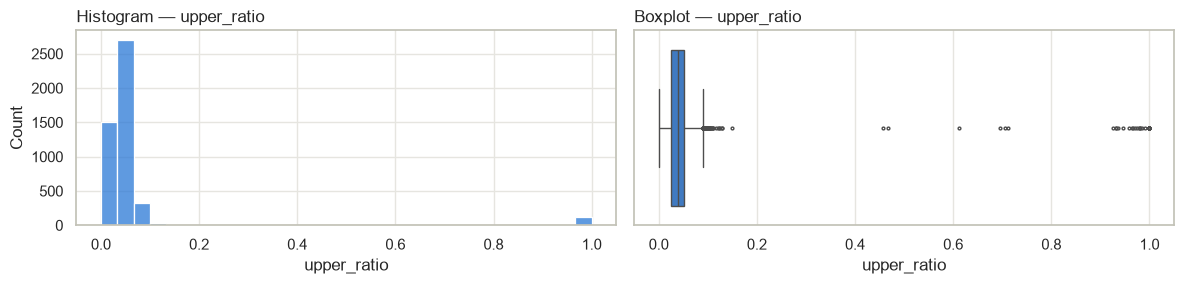

In [112]:
# Build the engineered numerical features on the TRAIN set only (for analysis)
X_train_fe = ReviewPreprocessor().fit_transform(X_train)
num_cols = ['helpful_votes', 'word_count', 'exclaim_count', 'upper_ratio']

def diagnostic_plots(data, variable):
    '''Histogram + boxplot for one variable.'''
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(data[variable], bins=30, color=MAIN_COLOR, ax=axes[0])
    axes[0].set_title(f'Histogram — {variable}', loc='left')
    sns.boxplot(x=data[variable], color=MAIN_COLOR, fliersize=2, ax=axes[1])
    axes[1].set_title(f'Boxplot — {variable}', loc='left')
    plt.tight_layout()
    plt.show()

for col in num_cols:
    diagnostic_plots(X_train_fe, col)

In [113]:
def outliers_checker(data, list_cols):
    '''Classify skewness and count outliers using the matching rule:
       normal -> mean ± 3 std, skewed -> IQR ×1.5, extreme skew -> IQR ×3.'''
    result = []
    for col in list_cols:
        s = data[col].dropna()
        skew = s.skew()
        if abs(skew) <= 0.5:
            dist = 'Normal'
            upper, lower = s.mean() + 3 * s.std(), s.mean() - 3 * s.std()
        else:
            dist = 'Skewed' if abs(skew) <= 1 else 'Extreme Skew'
            fold = 1.5 if dist == 'Skewed' else 3
            iqr = s.quantile(0.75) - s.quantile(0.25)
            upper, lower = s.quantile(0.75) + fold * iqr, s.quantile(0.25) - fold * iqr
        n_out = ((s > upper) | (s < lower)).sum()
        result.append([col, round(skew, 2), dist, round(lower, 2), round(upper, 2),
                       n_out, round(n_out / len(s) * 100, 2)])
    return pd.DataFrame(result, columns=['column', 'skewness', 'distribution', 'lower_bound',
                                         'upper_bound', 'n_outliers', 'pct_outliers'])

outliers_checker(X_train_fe, num_cols)

,column,skewness,distribution,lower_bound,upper_bound,n_outliers,pct_outliers
0,helpful_votes,10.53,Extreme Skew,-2.00,5.00,130,2.79
1,word_count,0.36,Normal,-2.54,31.62,12,0.25
2,exclaim_count,6.40,Extreme Skew,0.00,0.00,240,5.10
3,upper_ratio,5.44,Extreme Skew,-0.06,0.13,139,2.95


In [114]:
# Cap outliers with the custom IQRCapper (fold = 3 for extreme skew), fitted on TRAIN only
capper = IQRCapper(fold=3)
imputer = SimpleImputer(strategy='median')
train_num = imputer.fit_transform(X_train_fe[num_cols])
capped = pd.DataFrame(capper.fit_transform(train_num), columns=num_cols)

pd.DataFrame({'lower_cap': capper.lower_, 'upper_cap': capper.upper_,
              'max_before': X_train_fe[num_cols].max().values,
              'max_after': capped.max().values}, index=num_cols).round(2)

,lower_cap,upper_cap,max_before,max_after
helpful_votes,-2.00,5.00,396.0,5.00
word_count,-14.00,42.00,34.0,34.00
exclaim_count,0.00,1.00,3.0,1.00
upper_ratio,-0.06,0.13,1.0,0.13


> **Insight:**
- `helpful_votes`, `exclaim_count` and `upper_ratio` are **extremely right-skewed** (skewness 5–11). Most reviews have 0–2 votes and no exclamation marks, while a few viral or "shouting" reviews create long tails (up to 396 votes, 100% capital letters).
- `word_count` is close to normal and has almost no outliers.
- Outliers are **capped (winsorized), not removed**. These are real reviews, and removing them would delete exactly the angry or viral reviews the client cares about. The custom `IQRCapper` (fold = 3) learns the boundaries on the training data and is included in the pipeline, so new data is capped the same way. For `exclaim_count`, the IQR is 0, so the capper uses the 99th percentile as the upper limit.

## **5. Feature Selection**

In [115]:
# a) Columns dropped by design
dropped = pd.DataFrame({
    'column': ['review_id', 'customer_id', 'review_date', 'product_name', 'rating'],
    'reason': ['Unique identifier — no predictive meaning',
               'Identifier (high cardinality) — would cause overfitting',
               'Time stamp — patterns change over time; trends are monitored separately',
               '9 values fully nested in product_category; product-specific words are captured by TF-IDF',
               'DATA LEAKAGE — near-direct proxy of the label and unavailable for tickets/social text']})
dropped

,column,reason
0,review_id,Unique identifier — no predictive meaning
1,customer_id,Identifier (high cardinality) — would cause overfitting
2,review_date,Time stamp — patterns change over time; trends are monitored separately
3,product_name,9 values fully nested in product_category; product-specific words are captured by TF-IDF
4,rating,DATA LEAKAGE — near-direct proxy of the label and unavailable for tickets/social text


In [116]:
# b) Categorical features vs. sentiment -> Chi-square test of independence
cat_cols = ['verified_purchase', 'product_category', 'sales_channel', 'customer_region']
rows = []
for col in cat_cols:
    table = pd.crosstab(X_train_fe[col], y_train)
    chi2, p, dof, _ = chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append([col, round(chi2, 2), p, round(cramers_v, 3),
                 'Significant' if p < 0.05 else 'Not significant'])
pd.DataFrame(rows, columns=['column', 'chi2', 'p_value', 'cramers_v', 'status'])

,column,chi2,p_value,cramers_v,status
0,verified_purchase,5.33,2.554479e-01,0.024,Not significant
1,product_category,50.05,4.594264e-09,0.073,Significant
2,sales_channel,3.00,8.088472e-01,0.018,Not significant
3,customer_region,15.99,1.916880e-01,0.041,Not significant


In [117]:
# c) Numerical features vs. sentiment -> Kruskal-Wallis H-test (non-parametric, 3 groups)
rows = []
for col in num_cols:
    groups = [X_train_fe.loc[y_train == s, col].dropna() for s in SENTIMENT_ORDER]
    h, p = kruskal(*groups)
    rows.append([col, round(h, 2), p, 'Significant' if p < 0.05 else 'Not significant'])
pd.DataFrame(rows, columns=['column', 'H_statistic', 'p_value', 'status'])

,column,H_statistic,p_value,status
0,helpful_votes,848.78,4.898895e-185,Significant
1,word_count,17.63,1.483527e-04,Significant
2,exclaim_count,159.76,2.031555e-35,Significant
3,upper_ratio,192.95,1.260825e-42,Significant


> **Insight — final feature set:**
>
> | Feature | Decision | Reason |
> |---|---|---|
> | `review_title` + `review_text` → `clean_text` | **Keep** | Core signal of the model (TF-IDF) |
> | `word_count`, `exclaim_count`, `upper_ratio` | **Keep** | Significant in Kruskal-Wallis test (p < 0.05) |
> | `product_category` | **Keep** | Significant in Chi-square test (p < 0.001); Smart Home has more negative reviews |
> | `helpful_votes` | **Drop** | Statistically significant, but votes **accumulate days or weeks after a review is posted**. At the moment a new review must be triaged, it has ~0 votes, so using it would inflate offline scores (*temporal leakage*). It also does not exist for tickets or social posts. |
> | `sales_channel`, `verified_purchase`, `customer_region` | **Drop** | Not significant (p > 0.05) and Cramér's V ≈ 0.02–0.04 |
> | `review_id`, `customer_id`, `review_date`, `product_name`, `rating` | **Drop** | Identifiers, time stamp, redundancy and data leakage (see table above) |

## **6. Scaling & Encoding**

In [118]:
# Final feature groups (based on the selection above)
text_col = 'clean_text'
final_num_cols = ['word_count', 'exclaim_count', 'upper_ratio']   # helpful_votes dropped (timing leakage)
final_cat_cols = ['product_category']                               # only significant categorical feature

# Numerical: impute missing values -> cap outliers -> scale to [0, 1]
# MinMaxScaler is used (instead of StandardScaler) so all features stay non-negative,
# which keeps them on the same scale as TF-IDF weights and is required by Naive Bayes.
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('capper', IQRCapper(fold=3)),
    ('scaler', MinMaxScaler())
])

# Categorical nominal: One-Hot Encoding (unknown categories at inference are ignored)
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Text: TF-IDF with unigrams + bigrams (bigrams capture 'not good', 'stopped charging')
text_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True))
])

preprocessor = ColumnTransformer([
    ('text', text_pipeline, text_col),
    ('num', num_pipeline, final_num_cols),
    ('cat', cat_pipeline, final_cat_cols)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

In [119]:
# Quick check of the transformed feature matrix
_tmp = Pipeline([('prep', ReviewPreprocessor()), ('features', preprocessor)]).fit(X_train)
print('Number of features after encoding:', _tmp.transform(X_train).shape[1])

Number of features after encoding: 3386


> **Insight:** All preprocessing is combined in one `ColumnTransformer`:
- **Text** → TF-IDF with unigrams and bigrams, `min_df=2` (ignore one-off typos), `max_df=0.9` (ignore words that appear everywhere) and `sublinear_tf=True` (dampens repeated words).
- **Numerical** → median imputation → IQR capping → MinMax scaling to [0, 1].
- **Categorical** → constant imputation → One-Hot Encoding with `handle_unknown='ignore'`, so a new category at inference does not break the model.

The final matrix has **3,386 features**, almost all from TF-IDF.

---

# **IX. MODEL DEFINITION**

Five classification algorithms are compared. Every model is wrapped in the **same end-to-end pipeline** (`ReviewPreprocessor` → `ColumnTransformer` → classifier), so cleaning, feature creation, scaling and encoding are always fitted on training folds only — no data leakage during cross-validation.

1. **Logistic Regression** — a linear model that works very well on sparse TF-IDF features, is fast, outputs probabilities, and its coefficients show which words drive each sentiment (interpretable for the client).
2. **Linear Support Vector Machine (LinearSVC)** — maximises the margin between classes; one of the strongest classical baselines for text classification.
3. **Complement Naive Bayes** — a Naive Bayes variant designed for imbalanced text data; extremely fast and a common NLP baseline.
4. **Random Forest** — an ensemble of decision trees that captures non-linear interactions; included to test whether a non-linear model adds value.
5. **K-Nearest Neighbors (cosine distance)** — an instance-based baseline that classifies a review by its most similar reviews.

**Class imbalance:** `class_weight='balanced'` is used where supported so that the neutral and negative classes are not ignored.

**Evaluation metric:** **Macro F1-score** (the unweighted average of the F1 of each class). Accuracy would be misleading because ~58% of reviews are positive — a model that always predicts "positive" would reach 58% accuracy while being useless. Macro F1 gives equal importance to negative and neutral reviews, which are the ones the business cares about most.

In [120]:
def build_model(classifier):
    '''Full pipeline: raw reviews -> features -> classifier.'''
    return Pipeline([
        ('review_prep', ReviewPreprocessor()),
        ('features', preprocessor),
        ('classifier', classifier)
    ])

models = {
    'Logistic Regression': build_model(LogisticRegression(max_iter=2000, class_weight='balanced',
                                                          random_state=RANDOM_STATE)),
    'Linear SVM': build_model(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
    'Complement NB': build_model(ComplementNB()),
    'Random Forest': build_model(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                        n_jobs=-1, random_state=RANDOM_STATE)),
    'KNN (cosine)': build_model(KNeighborsClassifier(n_neighbors=15, metric='cosine', weights='distance'))
}

models['Logistic Regression']

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('review_prep', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defa

---

# **X. MODEL TRAINING**

In [121]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    model.fit(X_train, y_train)          # fit on the full training set for later evaluation
    cv_results.append([name, scores.mean(), scores.std(), scores.min(), scores.max()])
    print(f'{name:<20} | Macro F1 (5-fold CV): {scores.mean():.4f} ± {scores.std():.4f}')

cv_df = (pd.DataFrame(cv_results, columns=['model', 'cv_f1_mean', 'cv_f1_std', 'cv_f1_min', 'cv_f1_max'])
           .sort_values('cv_f1_mean', ascending=False).reset_index(drop=True))
cv_df.round(4)

Logistic Regression  | Macro F1 (5-fold CV): 0.8736 ± 0.0046
Linear SVM           | Macro F1 (5-fold CV): 0.8631 ± 0.0078
Complement NB        | Macro F1 (5-fold CV): 0.8640 ± 0.0082
Random Forest        | Macro F1 (5-fold CV): 0.8673 ± 0.0074
KNN (cosine)         | Macro F1 (5-fold CV): 0.7660 ± 0.0099


,model,cv_f1_mean,cv_f1_std,cv_f1_min,cv_f1_max
0,Logistic Regression,0.8736,0.0046,0.8658,0.8786
1,Random Forest,0.8673,0.0074,0.8567,0.8762
2,Complement NB,0.8640,0.0082,0.8538,0.8759
3,Linear SVM,0.8631,0.0078,0.8536,0.8743
4,KNN (cosine),0.7660,0.0099,0.7496,0.7800


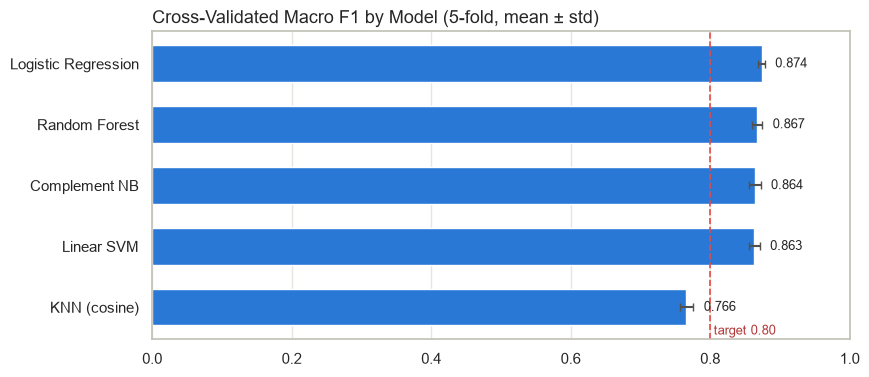

In [122]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_df = cv_df.sort_values('cv_f1_mean')
ax.barh(plot_df['model'], plot_df['cv_f1_mean'], xerr=plot_df['cv_f1_std'],
        color=MAIN_COLOR, height=0.6, error_kw={'ecolor': '#52514e', 'capsize': 3})
for i, v in enumerate(plot_df['cv_f1_mean']):
    ax.text(v + plot_df['cv_f1_std'].iloc[i] + 0.015, i, f'{v:.3f}', va='center', fontsize=9)
ax.axvline(0.80, color='#e34948', ls='--', lw=1.2)
ax.text(0.805, -0.45, 'target 0.80', color='#b23a39', fontsize=9)
ax.set_xlim(0, 1)
ax.set_title('Cross-Validated Macro F1 by Model (5-fold, mean ± std)', loc='left', fontsize=13)
ax.grid(axis='y', visible=False)
plt.show()

> **Insight:** Summary of 5-fold cross-validation (macro F1):
>
> 1. **Logistic Regression — 0.874 ± 0.005**: best mean score **and** the lowest variance across folds. This makes it the most stable model.
> 2. **Random Forest — 0.867 ± 0.007**: competitive, but much slower and less interpretable on 3,000+ sparse features.
> 3. **Complement NB — 0.864 ± 0.008**: a strong, very fast baseline, as expected for text data.
> 4. **Linear SVM — 0.863 ± 0.008**: close to Logistic Regression, but it does not output probabilities natively.
> 5. **KNN (cosine) — 0.766 ± 0.010**: clearly the weakest. Distance-based methods struggle in high-dimensional sparse TF-IDF space.
>
> Four of the five models already exceed the **0.80 target**. This confirms that the text features carry a strong signal.

---

# **XI. MODEL EVALUATION**

## **1. Train vs. Test Performance (Baseline Models)**

In [123]:
eval_rows = []
for name, model in models.items():
    y_tr_pred = model.predict(X_train)
    y_te_pred = model.predict(X_test)
    eval_rows.append([name,
                      f1_score(y_train, y_tr_pred, average='macro'),
                      f1_score(y_test, y_te_pred, average='macro'),
                      accuracy_score(y_test, y_te_pred),
                      recall_score(y_test, y_te_pred, labels=['negative'], average='macro')])

eval_df = pd.DataFrame(eval_rows, columns=['model', 'train_macro_f1', 'test_macro_f1',
                                           'test_accuracy', 'test_recall_negative'])
eval_df['gap_train_test'] = eval_df['train_macro_f1'] - eval_df['test_macro_f1']
eval_df.sort_values('test_macro_f1', ascending=False).round(4).reset_index(drop=True)

,model,train_macro_f1,test_macro_f1,test_accuracy,test_recall_negative,gap_train_test
0,Linear SVM,0.9139,0.8640,0.8921,0.8816,0.0499
1,Random Forest,0.9736,0.8627,0.8879,0.8849,0.1109
2,Logistic Regression,0.8880,0.8624,0.8895,0.8849,0.0256
3,Complement NB,0.8728,0.8572,0.8853,0.8947,0.0156
4,KNN (cosine),0.9996,0.7598,0.8114,0.7829,0.2398


> **Insight:**
- On the test set, the four linear and tree models score very close to each other (**0.857–0.864 macro F1**), and all reach ≥ 0.88 recall on the negative class.
- **Random Forest** and **KNN** show clear **overfitting**: train F1 is 0.97–1.00 but test F1 is much lower (gap of 0.11 and 0.24).
- **Logistic Regression** has one of the smallest train–test gaps (**0.026**). Together with the best CV score, this means it generalises best.
- **Selected model: Logistic Regression.** It has the best and most stable cross-validation score, little overfitting, **probability outputs** (useful for prioritising which reviews the CX team should handle first) and **interpretable coefficients** that show the client *why* a review is classified as negative. Linear SVM scores slightly higher on this one test split (+0.002), but model selection is based on cross-validation, not on a single split.

## **2. Hyperparameter Tuning**

In [124]:
param_grid = {
    'features__text__tfidf__ngram_range': [(1, 1), (1, 2)],
    'features__text__tfidf__min_df': [1, 2, 3],
    'classifier__C': [0.1, 0.25, 0.5, 1, 2, 5]
}

grid_search = GridSearchCV(models['Logistic Regression'], param_grid=param_grid,
                           scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print('Best parameters :', grid_search.best_params_)
print('Best CV Macro F1:', round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters : {'classifier__C': 0.25, 'features__text__tfidf__min_df': 2, 'features__text__tfidf__ngram_range': (1, 2)}
Best CV Macro F1: 0.8746


> **Insight:** The grid search (36 combinations × 5 folds = 180 fits) selected **C = 0.25** (stronger regularisation), **unigrams + bigrams** and **min_df = 2**. CV macro F1 improved slightly from **0.8736 to 0.8746**. The gain is small, which shows that the default configuration was already close to optimal. The main benefit of the lower `C` is a **simpler, more regularised model** that is less likely to overfit as new vocabulary appears over time.

## **3. Final Model Evaluation on the Test Set**

In [125]:
best_model = grid_search.best_estimator_
y_test_pred = best_model.predict(X_test)
y_train_pred = best_model.predict(X_train)

print('Train Macro F1 :', round(f1_score(y_train, y_train_pred, average='macro'), 4))
print('Test  Macro F1 :', round(f1_score(y_test, y_test_pred, average='macro'), 4))
print('Test  Accuracy :', round(accuracy_score(y_test, y_test_pred), 4))
print()
print(classification_report(y_test, y_test_pred, labels=SENTIMENT_ORDER, digits=3))

Train Macro F1 : 0.8799
Test  Macro F1 : 0.8593
Test  Accuracy : 0.8853

              precision    recall  f1-score   support

    negative      0.846     0.885     0.865       304
     neutral      0.733     0.855     0.789       186
    positive      0.956     0.894     0.924       687

    accuracy                          0.885      1177
   macro avg      0.845     0.878     0.859      1177
weighted avg      0.893     0.885     0.887      1177



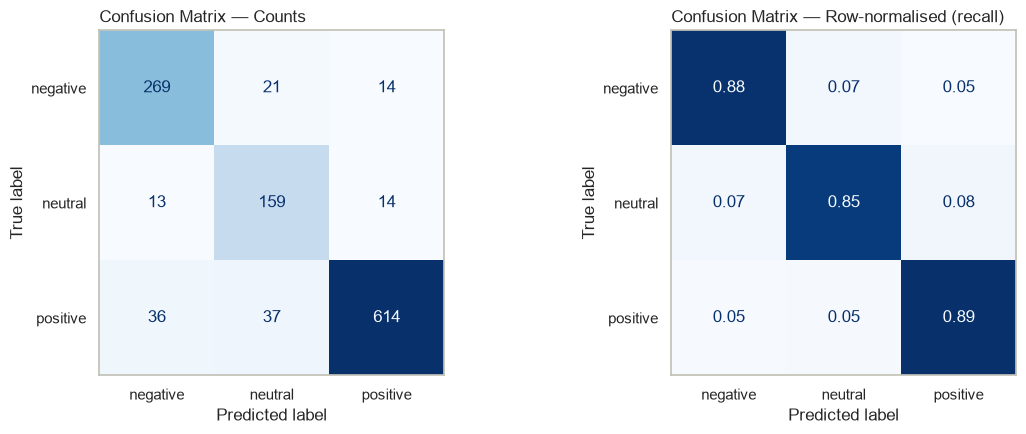

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Row-normalised (recall)']):
    ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, labels=SENTIMENT_ORDER,
                                            normalize=norm, cmap='Blues', colorbar=False,
                                            values_format='d' if norm is None else '.2f', ax=ax)
    ax.set_title(f'Confusion Matrix — {title}', loc='left')
    ax.grid(False)
plt.tight_layout()
plt.show()

> **Insight — final model performance on unseen data (1,177 reviews):**
>
> | Metric | Result | Target | Status |
> |---|---|---|---|
> | Macro F1 | **0.859** | ≥ 0.80 | ✅ Achieved |
> | Recall — negative | **0.885** | ≥ 0.85 | ✅ Achieved |
> | Accuracy | 0.885 | — | — |
>
> - The train F1 (0.880) and test F1 (0.859) are close, so the model is a **good fit**, with no significant overfitting or underfitting.
> - **Positive** is predicted with very high precision (0.956): when the model says a review is positive, it is almost always right.
> - **Negative** recall is 0.885: only 35 of 304 negative reviews were missed (14 predicted as positive, 21 as neutral). For the CX team, this means about 9 out of 10 unhappy customers are flagged automatically.
> - **Neutral** is the hardest class (F1 0.789, precision 0.733). Most errors are between neutral and its neighbours. This is expected, because neutral reviews mix positive and negative statements, and even human annotators disagree on them.

## **4. Model Interpretation: Which Words Drive Each Sentiment?**

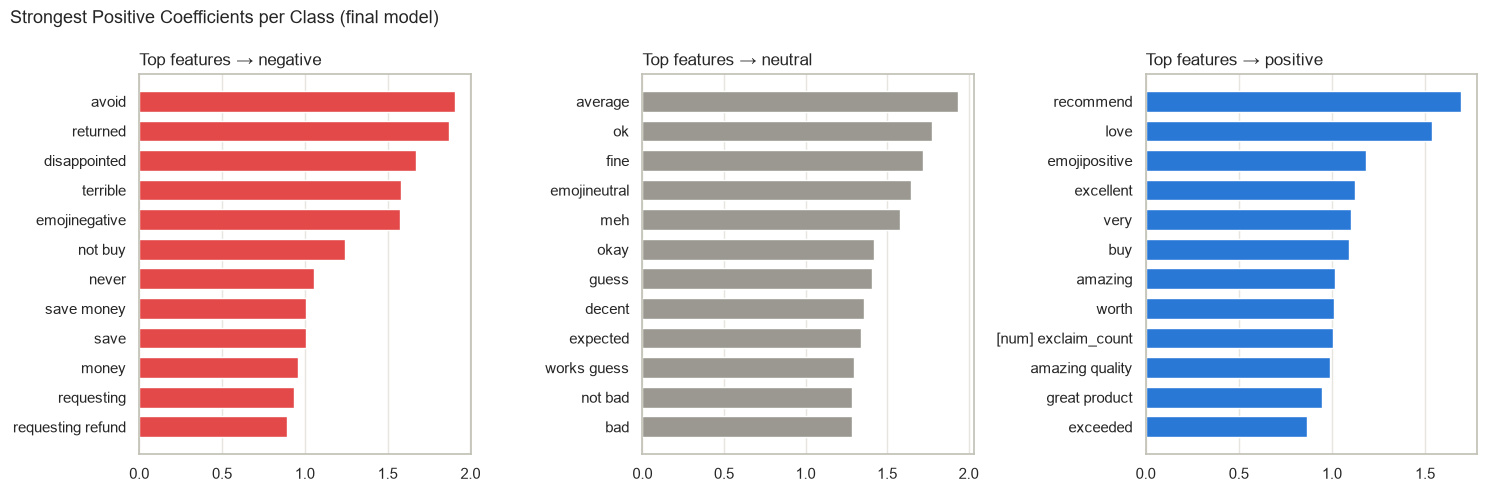

In [127]:
feature_names = best_model.named_steps['features'].get_feature_names_out()
coefs = best_model.named_steps['classifier'].coef_
classes = best_model.named_steps['classifier'].classes_

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, s in zip(axes, SENTIMENT_ORDER):
    idx = list(classes).index(s)
    top = np.argsort(coefs[idx])[-12:]
    labels = [feature_names[i].replace('text__', '').replace('num__', '[num] ').replace('cat__', '[cat] ')
              for i in top]
    ax.barh(labels, coefs[idx][top], color=PALETTE[s], height=0.7)
    ax.set_title(f'Top features → {s}', loc='left')
    ax.grid(axis='y', visible=False)
plt.suptitle('Strongest Positive Coefficients per Class (final model)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

> **Insight:** The model learned intuitive, explainable patterns:
- **Negative** — *avoid, returned, disappointed, terrible, not buy, requesting refund, save money* and the negative emoji token. Bigrams such as *not buy* and *requesting refund* show why negations were kept and bigrams were added.
- **Neutral** — hedging language: *average, ok, fine, meh, decent, expected, not bad, works guess*.
- **Positive** — *recommend, love, excellent, amazing quality, great product, worth*. The engineered feature `exclaim_count` is also among the top positive features: enthusiastic customers use exclamation marks.

This transparency matters for the client. The CX team can see *why* a review was flagged, which builds trust in the model.

## **5. Error Analysis**

In [128]:
errors = X_test.assign(actual=y_test, predicted=y_test_pred)
errors = errors[errors['actual'] != errors['predicted']]
print('Misclassified reviews in test set:', len(errors), 'of', len(X_test))
errors[['review_text', 'actual', 'predicted']].sample(8, random_state=RANDOM_STATE)

Misclassified reviews in test set: 135 of 1177


,review_text,actual,predicted
4261,Does the job. Arrived two days early. Pairing fails constantly. Can't decide if I'd buy again.,positive,neutral
1441,"Build quality is flimsy. On the other hand, great value for money. Save your money.",positive,negative
4362,Not worth the money. more info: https://www.reddit.com/r/gadgets,positive,negative
1530,REGRET BUYING THESE PLUGS. CUSTOMER SERVICE NEVER REPLIED. SAVE UR MONEY.,neutral,negative
1488,Battery drains way too fast. The cable frayed within a month. Not worth the money. Avoid.,positive,negative
4648,"It's ok. Connects to my phone in seconds. Had to contact support once, they eventually helped. Might keep it.",negative,neutral
849,"does the job. image is acceptable, not really 2k. way overpriced for what u get. more info: https://www.reddit.com/r...",positive,neutral
4426,Does the job. It won't hold a charge anymore. Pairing took a coulpe of tries but works now. Might keep it.,positive,neutral


> **Insight:** Reading the misclassified reviews (135 of 1,177, 11.5%) shows two main types of errors:
1. **Possible annotation noise (the most common case in this sample):** several reviews with clearly negative text are labelled positive or neutral, e.g., *"Battery drains way too fast… Not worth the money. Avoid."* (labelled positive) or *"REGRET BUYING THESE PLUGS… SAVE UR MONEY."* (labelled neutral). In these cases the model's prediction (negative) is arguably **more correct than the label**. A short label audit is recommended before the next retraining.
2. **Genuinely mixed or hedged reviews**, e.g., *"Does the job. It won't hold a charge anymore. Pairing took a couple of tries but works now."* (labelled positive, predicted neutral). These combine praise and complaints, and even human annotators often disagree on them.

Bag-of-words models also cannot fully capture sarcasm or long-range context. A transformer model (e.g., DistilBERT/RoBERTa) is a natural next step if higher neutral-class performance is needed.

---

# **XII. MODEL SAVING**

In [129]:
# Save the complete pipeline (preprocessing + feature engineering + classifier)
with open('models/best_model_sentiment.pkl', 'wb') as file:
    pickle.dump(best_model, file)

print('Model saved to models/best_model_sentiment.pkl')

Model saved to models/best_model_sentiment.pkl


> The final **tuned Logistic Regression pipeline** has been saved as `models/best_model_sentiment.pkl`. The file contains every step — text cleaning, feature creation, imputation, outlier capping, scaling, one-hot encoding, TF-IDF vectorisation and the classifier — so new reviews can be scored in their **raw** form. The helper module `text_utils.py` must be available in the same folder when the model is loaded.

---

# **XIII. MODEL INFERENCE**

*Separate from this notebook — see `model_inference.ipynb`.*

---

# **XIV. CONCLUSION**

**Project summary**

This project delivered an end-to-end sentiment classification pipeline for a direct-to-consumer consumer electronics business. The pipeline reads **raw** customer reviews and classifies them as positive, neutral or negative. After cleaning 6,130 raw records (duplicates, blank texts, inconsistent labels, HTML, emojis and slang), five models were compared using 5-fold cross-validation. A **tuned Logistic Regression** with TF-IDF (unigrams + bigrams) and three engineered text features was selected.

**Results vs. SMART goals**

| Goal | Target | Result |
|---|---|---|
| Macro F1 on unseen data | ≥ 0.80 | **0.859** ✅ |
| Recall on negative reviews | ≥ 0.85 | **0.885** ✅ |
| Reusable pipeline + inference notebook | Within 4 weeks | Delivered ✅ |

The model does **not** use the star rating (to avoid leakage). It can therefore also be applied to support tickets, chat logs and social-media comments.

**Key business insights**

1. **Earbud connectivity incident:** negative sentiment for the AirPulse Pro Earbuds more than doubled in **Aug–Oct 2025** (≈20% → 51–55%), and 67% of those complaints mention connectivity. Automated monitoring would have detected this within weeks.
2. **Smart Home app:** the security camera and smart plug have the highest negative share (~33%), and **62% of their negative reviews mention the app**. The companion app should be the top priority on the product roadmap.
3. **Service issues drive many complaints:** customer support (27%) and shipping (25%) are the most frequent aspects in negative reviews. Both can be improved without changing the hardware.
4. **Power bank pricing:** the VoltMax 20K has the highest neutral share (26%). This suggests a value-perception issue that could be tested with pricing or bundling.
5. **Holiday logistics:** marketplaces (Best Buy, Amazon) show a small increase in negative reviews in December, while the Official Webstore does not.

**Recommendations for the client**

- **Deploy** the pipeline as a daily batch job on new reviews and feed the results into a dashboard with alerts when the weekly negative share of any product exceeds its normal range (e.g., +10 points).
- **Prioritise** responses using the predicted negative probability, so that the most clearly unhappy customers are contacted first.
- **Extend** the model to support tickets and social mentions (no star rating required).

**Next steps for the model**

- Run a short **label-audit** round on ambiguous and misclassified reviews to reduce annotation noise.
- Add **aspect-based sentiment** (sentiment per topic: battery, app, shipping, etc.) to complement the keyword analysis.
- Test a **transformer model** (DistilBERT / RoBERTa) for better handling of sarcasm and mixed reviews, and compare the gain against its higher serving cost.
- **Monitor drift** (new products, slang and complaint topics) and retrain the model every quarter.